> **Recommended: run this notebook in Google Colab, nothing to install.**
>
> [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/examples/mainline-and-feeders.ipynb)
>
> Just click on the "Open in Colab" button and follow along. Click the ▶ button on each cell (or press Shift+Enter) to see the results and move on to the next one.
>
> If you can't or don't want to use Colab, the documentation website shows the pre-run results.

# A mainline and its feeders

[Regional networks](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/examples/regional-networks.html) · deck `simulations/examples/example_1/`

How do two ship sizes on connected routes choose fuels when the ports supply them
unevenly?

## The case

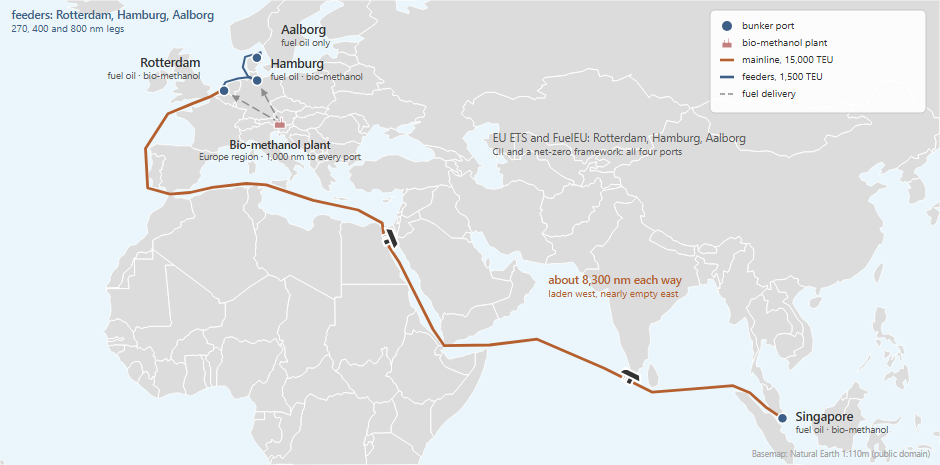

- **Ships:** two fleets on two routes. 5 mainline container ships
  (~15,000 TEU), four in five on fuel oil, the rest on methanol; 50 feeders
  (~1,500 TEU), almost all on fuel oil. Both can order or convert to methanol
  ships.
- **Routes:** the mainline sails Singapore to Rotterdam, 8,300 nm each way in the
  deck, laden west and nearly empty east; the feeders sail Rotterdam, Hamburg
  and Aalborg.
- **Fuels:** fuel oil at every port; bio-methanol from a European plant, at
  every port but Aalborg.
- **Policy:** EU ETS and FuelEU on the three European ports; CII and a net-zero
  framework on all four, the framework with values that are the deck's own, not
  the data library's.
- **Horizon:** 2026 to 2050, yearly.
- **Freight rate:** container ships carry TEU, so the freight rate here is per
  thousand TEU-miles: do not compare it with the bulk carriers'.

## Results

In [1]:
# @title Setup
# Setup. Works both on Google Colab and in a local checkout of the repository.
import os
from pathlib import Path


# The branch these notebooks live on, and the one Colab clones. The "Open in
# Colab" badge at the top of the notebook, like the links between the
# notebooks, opens the copy on the workshop-colab branch instead: the same
# notebooks with their outputs cleared, rebuilt from this branch by
# .github/workflows/workshop-colab.yml. Change BRANCH, and that workflow, to
# "main" once the branch has been merged.
BRANCH = "dev-workshop"


def at_repo_root() -> bool:
    """True if the working directory is the root of the repository."""
    return Path("navigate").is_dir() and Path("assumptions").is_dir()


if at_repo_root():
    print("Already at the repository root.")
elif Path("../../navigate").is_dir():
    # Local Jupyter starts the kernel in the notebook's own folder,
    # docs/workshop/, but the paths below are relative to the repository root.
    os.chdir("../..")
    print("Moved up to the repository root.")
else:
    # Colab, or any other fresh environment
    if not Path("navigate-zcs").is_dir():
        !git clone --depth 1 -b {BRANCH} https://github.com/zerocarbonshipping/navigate-zcs.git
    os.chdir("navigate-zcs")
    print("Cloned the repository and moved into it.")

assert at_repo_root(), f"not at the repository root: {Path.cwd()}"

# `import navigate` is not a usable test here: from the repository root it
# succeeds because the source folder is present, even when the `navigate`
# command itself is missing.
import sys
from importlib.metadata import PackageNotFoundError, version

try:
    print(f"Navigate {version('navigate-zcs')} is already installed.")
except PackageNotFoundError:
    %pip install -q .
    print("Installed Navigate.")


# The example deck.
EXAMPLE = Path("simulations/examples/example_1")
assert EXAMPLE.is_dir(), (
    f"{EXAMPLE} not found under {Path.cwd()}. On Colab the setup cell clones the "
    f"{BRANCH!r} branch, so this deck has to be committed and pushed there."
)


Moved up to the repository root.
Navigate 1.0.0 is already installed.


The cell below solves the case from 2026 to 2050 and draws its well-to-wake emissions, its freight rate and the fuel it burns.

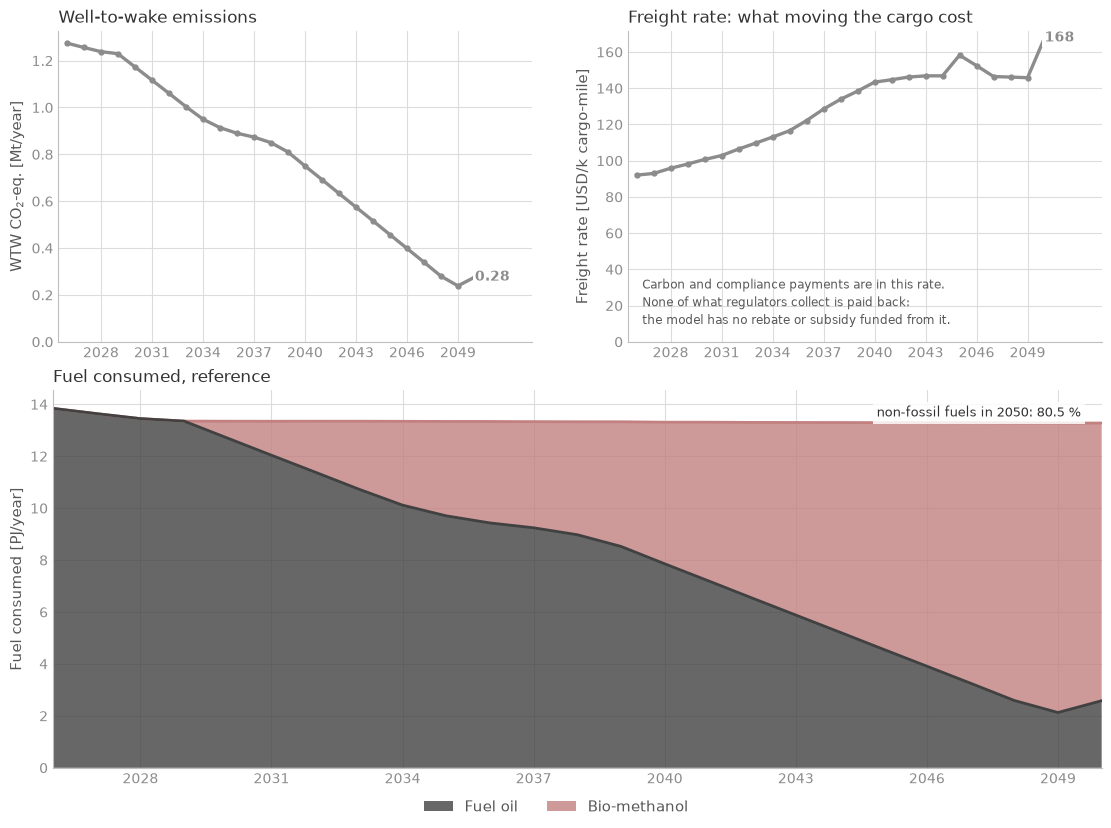

In [2]:
# @title Run the case and see the results
import sys
from pathlib import Path

import matplotlib.pyplot as plt

# The workshop's figure and the functions that fill it, shared with the
# Examples pages: docs/workshop/_results.py.
sys.path.insert(0, str(Path("docs/workshop").resolve()))
from _results import compare_with_previous, plot_cases, print_summary, run_case, scale, summarise
from _solver import guard_interior_point

guard_interior_point()

NAV = Path("simulations/examples/example_1/example_1.nav")
REF_TWEAK = None
_m = run_case(NAV)
ref = summarise(_m)
plot_cases({"reference": ref}, annotate=True)
plt.show()


# ===========================================================================
#  The machinery for the sensitivity analysis. Nothing to edit here: the
#  levers are further down.
# ===========================================================================
# each lever, and the forecasts it multiplies
LEVERS = {
    "OIL_PRICE": ['fossil_fuel_oil_price_global'],
    "EU_ETS_PRICE": ['eu_ets_carbon_credit_price'],
    "BIOMASS_COST": ['feedstock_biomethanol_gasification_cost'],
}
_RUNS = []      # the scenarios solved so far, newest last: (levers, summary)


def run_your_scenario():
    """Solve the levers set in the YOUR SCENARIO cell and compare with
    the reference and with the scenario solved before it."""
    changed = [(n, globals()[n]) for n in LEVERS if globals()[n] != 1.0]
    if not changed:
        print("Every lever is still at 1.0, so this would just re-solve the deck.")
        print("Change one of the numbers above and run this cell again.")
        return
    tweaks = ([REF_TWEAK] if REF_TWEAK else []) + [scale(f, v) for n, v in changed
                                                   for f in LEVERS[n]]

    def your_scenario(m):
        for t in tweaks:
            t(m)

    label = ",  ".join(f"{n} x {v}" for n, v in changed)
    compare_with_previous(NAV, ref, your_scenario, label, _RUNS, ref_label="reference")
    plt.show()


### Move one lever

Each number multiplies what the deck already says, so 1.0 is the reference. Set one, run the cell, and compare with the reference and with the scenario you ran before. As an example, OIL_PRICE is set to 2.0: the fuel oil price doubled.

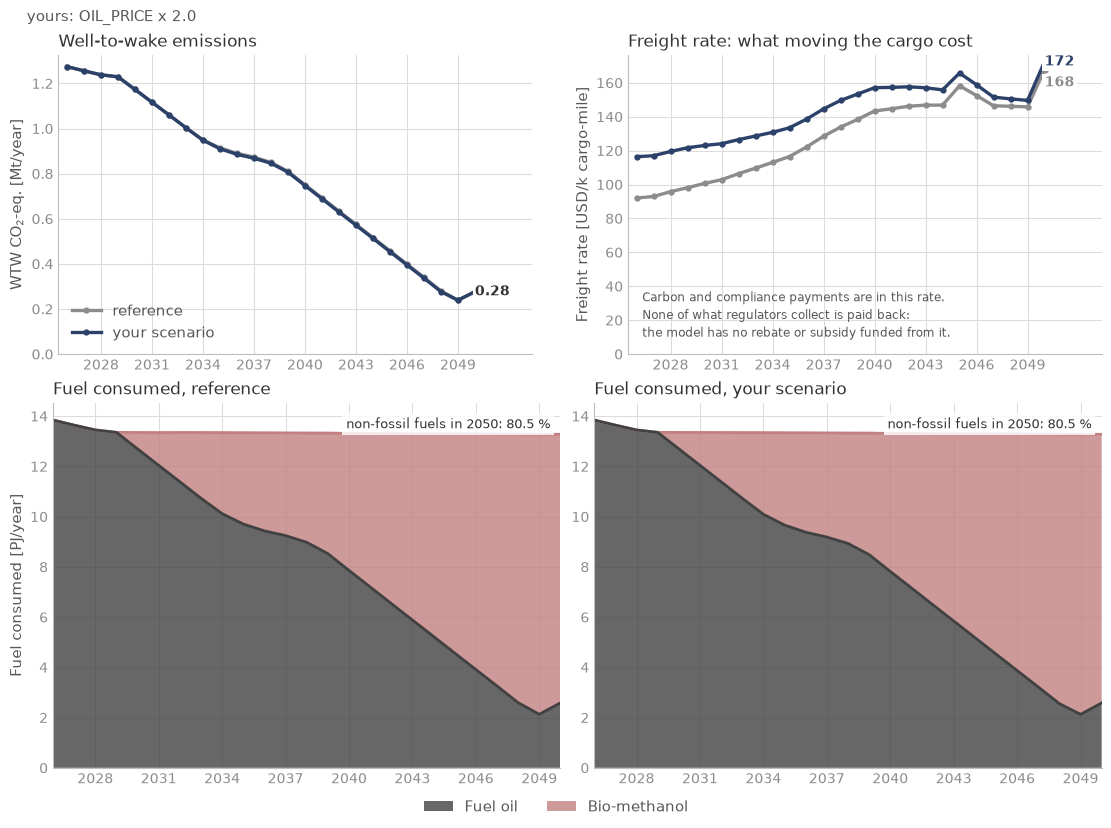

In [3]:
# ===========================================================================
#  YOUR SCENARIO.  Set a lever, then run this cell: it solves your scenario
#  and compares it with the reference and with the scenario you ran before it.
#
#  Every number is a MULTIPLIER on what the deck already says, so 1.0 is the
#  deck. The right-hand column says what each 1.0 is worth, so you can judge
#  whether a factor of two is a big change or a small one.
#
#  As an example, OIL_PRICE is set to 2.0: the fuel oil price doubled.
#  Set OIL_PRICE back to 1.0 to start from the deck.
#
#                       suggested span  what 1.0 means in the deck
OIL_PRICE    = 2.0   #  0.7 - 2.0       485 USD/t, flat to 2050
EU_ETS_PRICE = 1.0   #  0.5 - 3.0       126 USD/t in 2026, 417 by 2050
BIOMASS_COST = 1.0   #  0.25 - 2.0      65 USD per dry t of the biomass bio-methanol is made from, flat
# ===========================================================================

run_your_scenario()


## The deck

In [4]:
# @title The deck, tab by tab
import sys
from pathlib import Path

sys.path.insert(0, str(Path("docs/workshop").resolve()))
from _deck import show_deck

show_deck(EXAMPLE, {
    "example_1.nav": ['example_1.nav'],
    "Fleets": ['includes/mainlines.inc', 'includes/feeders.inc', 'includes/mainlines_curves.inc', 'includes/feeders_curves.inc'],
    "Routes": ['includes/route.inc', 'includes/ports.inc', 'includes/bunker_logistics.inc'],
    "Fuel": ['includes/fuel_production.inc', 'includes/regions.inc', 'includes/producer.inc'],
    "Regulation": ['includes/cii.inc', 'includes/eu_ets.inc', 'includes/fuel_eu.inc', 'includes/net_zero_framework.inc'],
    "Decisions and report": ['includes/decision_processes.inc', 'includes/report.inc'],
})


# ---- example_1.nav ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# ------------------------------------------------------------------------------
# SETTING THE SCENE - EXAMPLE 1 (CONTAINER/FEEDER NETWORK)
#
# In this scenario, we follow a shipping company operating a logistics network
# composed of large mainline container vessels and smaller regional feeder ships.
#
# The mainline ships sail a global route between Singapore and Rotterdam, carrying 
# international cargo across 11,000 nautical miles. Once in Europe, feeder vessels 
# take over the distribution: sailing to Hamburg (a major port with strong infrastructure), 
# and Aalborg (a smaller, less-equipped port).
#
# Each vessel type faces different realities — from fuel infrastructure and technology choices 
# to emissions regulations and upgrade constraints. The example captures these variations
# through specific assumptions about fuels, fleet aging, emissions policy, and routing.
#
# This case is designed as a step up from basic tutorials. It allows users to explore dynamic 
# interactions between fuel switching, regulatory costs, and operational performance
# without the full complexity of large-scale models.
#
# Use the .inc files to explore, adjust, and analyze how vessel behavior changes
# under evolving market and policy conditions.
# ------------------------------------------------------------------------------

DEFINE {
	# -------------------------- DEFINITIONS --------------------------
    # Import the default model configuration for start
    # date and global warming potential lifetime
	Load DefaultModelDefinition

    # ---------------------------- FLEET ---------------------------
    # Define the available vessel options, including
    # the composition of the existing fleet
    Include "includes/mainlines_curves.inc"
    Include "includes/mainlines.inc"
    Include "includes/feeders_curves.inc"
    Include "includes/feeders.inc"

    # ----------------------- ROUTE ------------------------
    # Define the routes the vessels are operating on, including the
    # bunker price of fossil fuels and handling costs in ports
    Include "includes/route.inc"
    Include "includes/ports.inc"
    Include "includes/bunker_logistics.inc"

    # --------------------------- FUEL -----------------------------
    # Define the fuel plants that can be built
    # to meet the demand signals from the fleet
    Include "includes/fuel_production.inc"
    Include "includes/regions.inc"
    Include "includes/producer.inc"
    Load DefaultEmission

    # ------------------------ REGULATION --------------------------
    # We also have to take into account the different regulations in place 
    # in the operating areas. These include the FuelEU, Cii, NZF and EU ETS.
    Include "includes/cii.inc"
    Include "includes/eu_ets.inc"
    Include "includes/fuel_eu.inc"
    Include "includes/net_zero_framework.inc"

    # ---------------- DECISION PROCESESS ---------------------------
    Include "includes/decision_processes.inc"

    # -----------------------EXPORT -----------------------------
    Include "includes/report.inc"

    # -------------------------- OUTPUT -----------------------------
    Load DefaultPlot
}

EVENTS {
    # time-steps
	Load DefaultTimeStepYearly
}
# ---- includes/mainlines.inc ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# ---------------------------- CONTAINER FLEET --------------------------------------
#
# This file defines the mainline container fleet used in the scenario, which operates 
# along the long-haul route between Singapore and Rotterdam — a key global trade corridor.
#
# The fleet begins with a number of oil-fueled vessel nearing the end of their operational life
# creating a decision point: should the company reinvest in traditional fossil ships or 
# trans

## Build it with an AI assistant

The prompt below rebuilds this deck exactly: an assistant that saw only the
prompt reproduced its results to the tonne. The deck's own numbers are in it as
the person's numbers, marked GIVEN, so they are not a source. A network of
connected routes starts from it. [Session 5](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/workshop/05-build-your-own-case.html)
shows how to use it.

<details>
<summary>Full prompt for this case</summary>

<!-- tested-prompt: 3ee1ae5f7e49 -->
**The study.** The deck `simulations/examples/example_1`, rebuilt from a prompt:
5 container ships of 15,000 TEU on a Singapore - Rotterdam mainline, and 50
feeders of 1,500 TEU on a Rotterdam - Hamburg - Aalborg loop, 2026 to 2050,
under CII, EU ETS, FuelEU Maritime and a net-zero framework. Both fleets can
burn fuel oil or bio-methanol, made in Europe; Aalborg sells no bio-methanol. The
question is how two ship sizes on connected routes choose fuels when the ports
supply them unevenly.

**What comes from the library.** The four container ship designs, the fuels, the
bio-methanol process, its feedstock and their costs, fuel oil's price and
upstream emissions, electricity and grid emissions in Europe, the EU ETS price
and phase-in, FuelEU's target and default emission factors.

**What is GIVEN.** Everything else is the example deck's own: the fleet sizes and
ages, the routes, the bunker logistics, the handling costs, the plant capacity,
the producer's feedstock ceiling, the conversion costs, the regulations' settings
and the net-zero framework's targets and price. The prompt gives them as the
person's numbers, so the build uses them as they are; none is a source.

**Limits.** A few ships per fleet, not a market segment: Navigate decides in
fractions of ships. The `.nav` header of example_1 says 11,000 nm; its route,
which this prompt follows, says 8,300 nm.

**Tested:** 2026-10-30, built cold on Sonnet and on Haiku: both decks ran with
no warnings and reproduce example_1 to the tonne. The plant then gained the
library's cost of capital (it was financed at 0 %), and the wording was fixed
from the builders' notes; built cold again on Haiku, it reproduces the new
deck to the tonne: 1,274,745 t CO2e in 2026, 914,092 t in 2035 and 276,588 t
in 2050, when bio-methanol is 10.69 PJ of the 13.28 PJ burnt.

````text
You are helping me build a simulation study for Navigate, the shipping
decarbonisation model. Write the files yourself; do not only
describe them.

Before writing anything, find the Navigate repository on my machine (a folder
usually named navigate-zcs; ask me where it is if you cannot find it), then read
docs/workshop/building-a-deck.md in it and follow it. It
says how Navigate works, how to run a deck and read its results, and the rules
every deck follows. This prompt gives the case.

This case rebuilds the example deck simulations/examples/example_1 from this
prompt; you may read that deck. Every number below is mine: use it as given and
mark it GIVEN. The fleets are a few ships on purpose. You should not need to
invent anything: if you do, tell me what was missing.

THE DECK
A new folder, simulations/user/mainline_feeders/, with mainline_feeders.nav and
these files in includes/, included in this order: mainlines_curves.inc,
mainlines.inc, feeders_curves.inc, feeders.inc, route.inc, ports.inc,
bunker_logistics.inc, fuel_production.inc, regions.inc, producer.inc, then
Load DefaultEmission, then cii.inc, eu_ets.inc, fuel_eu.inc,
net_zero_framework.inc, decision_processes.inc, report.inc.
DEFINE starts with Load DefaultModelDefinition and ends with Load DefaultPlot;
EVENTS holds Load DefaultTimeStepYearly only. You may add Load DefaultReport to
read the results. Load nothing else: no DefaultRegulation, no
DefaultBunkerLogistics, no DefaultCalibration (decision_processes.inc holds
the deck's own).

THE CASE
A container network, 2026 to 2050, yearly steps: mainline ships from Singapore
to Rotterdam, and feeders from Rotterdam to Hamburg and Aalborg. Fuels: fuel oil
and bio-methanol, made in Europe.

FLEETS
- Fleet "mainlines": Copy Vessel container_15000_teu_ice_oil to mainline_oil and
  container_15000_teu_ice_methanol to mainline_methanol. 5 ships, split 0.8 oil,
  0.2 methanol. Ages (Curves age_dist_mainlines_oil and
  age_dist_mainlines_methanol, one row per age 0 to 24, 0 where not listed):
  oil 0.25 at ages 3, 6, 9 and 12; methanol 1 at age 0.
  set_fuel_conversion_cost("mainline_oil", "mainline_methanol", 24.3e6).
  AllowSpeedManagement = TRUE, MaximumSpeedChange = 0.5. No TradeGrowth line.
- Fleet "feeders": Copy Vessel container_1500_teu_ice_oil to feeder_oil and
  container_1500_teu_ice_methanol to feeder_methanol. 50 ships, split 0.96 oil,
  0.04 methanol. Ages (Curves age_dist_feeders_oil and
  age_dist_feeders_methanol): oil 0.04 at every age 0 to 24; methanol 0.5 at
  ages 0 and 2. set_fuel_conversion_cost("feeder_oil", "feeder_methanol",
  10.3e6). AllowSpeedManagement = FALSE, MaximumSpeedChange = 0.5. No
  TradeGrowth line.
- Decision processes, for Fleet "*": InterFuelSensitivity 0.5,
  IntraFuelSensitivity 0.5, FuelConversionSensitivity 2. For
  producer_methanol_bio: FuelDemandSensitivity 1.25, FuelCostSensitivity 0.5.

ROUTES (Vessel "mainline_*" and Vessel "feeder_*" each set their Route)
- mainline_route: ROUND_TRIP, singapore - rotterdam; PortDurations 1.5, 1.0;
  Distances 8300, 8300; Speeds 15.5, 14.2; CapacityUtilizations 0.95, 0.1.
- feeder_route: ROUND_TRIP, rotterdam - hamburg - aalborg; PortDurations 1.5,
  1.0, 1.0; Distances 270, 400, 800; Speeds 13.0, 12.5, 13.0;
  CapacityUtilizations 1.0, 0.7, 0.0.

PORTS
- methanol_bio may be bunkered at singapore, rotterdam and hamburg, not at
  aalborg; fossil_fuel_oil at every port.
- At every port (Port "*"): fuel oil's bunker price is overwritten with
  Forecast fossil_fuel_oil_price_global and its upstream CO2 with Forecast
  fossil_fuel_oil_wtt_carbon_dioxide; handling cost Variable handling_cost_oil
  = 8 and Variable handling_cost_methanol = 18 (declare both: the library has
  neither).
- BunkerLogistics: fossil_fuel_oil is the only liquid market fuel;
  set_distance("*", "*", 1000); set_transport_cost("*", 0.1).

FUEL PRODUCTION
- Import Fuel fossil_fuel_oil and methanol_bio; Import Source grid; Import
  Process methanol_synthesis_bio_gasification; Import Feedstock
  feedstock_biomethanol_gasification; Import Transport truck.
- Import Plant plant_methanol_bio_gasification and set its Region europe, Source
  grid, and Capacity = Forecast methanol_bio_gasification_plant_capacity, which
  you declare in the deck with my values, 100 in 2030 and 100 in 2050,
  extrapolated linearly (it replaces the library's Forecast of that name), and
  CostOfCapital = Forecast cost_of_capital_plant_bio_europe.
- Region "europe", declared (not imported), with three lines: source opex of
  grid = electricity_cost_europe_mid; feedstock cost of
  feedstock_biomethanol_gasification = feedstock_biomethanol_gasification_cost;
  source WTT CO2 of grid = grid_emissions_europe.
- Region "*": truck transport cost 0, truck CO2 = truck_emissions;
  methanol_synthesis_bio_gasification capex, opex and energy from the Forecasts
  of the same name with _capex, _opex, _energy; its process CO2 =
  -Variable carbon_dioxide_per_methanol.
- Producer "producer_methanol_bio": that one plant, MaximumDevelopment 1, feed
  constraint on feedstock_biomethanol_gasification = Forecast
  feedstock_biomethanol_gasification_constraint, which you declare (the library
  has none): 0.03e6 in 2025, 0.15e6 in
  2030, 0.90e6 in 2035, 1.14e6 in 2040, 1.26e6 in 2045, 1.38e6 in 2050,
  extrapolated linearly.

POLICY (each Regulation written in full, not copied from the library; each has
Fuels = Fuel("*") and set_include_vessel("*", TRUE))
- cii: TRANSPORT_NOMINAL, INDIVIDUAL, TTW, IncludeSlip FALSE, CO2 only, all four
  ports, RemedialCost 0 (it only tracks compliance). TTW CO2 3.114 for
  fossil_fuel_oil and 0.3 for methanol_bio. Thresholds: Forecast
  cii_target_reduction (1.0 in 2019, 0.99, 0.98, 0.97, 0.95, 0.93, 0.91, 0.89,
  0.87, 0.85, 0.83, 0.81 in 2030, one per year on 1 January, flat after),
  copied to cii_target_container_1500_teu (Multiplier 14.93) for feeder_* and
  to cii_target_container_15000_teu (Multiplier 5.66) for mainline_*. Vessel
  capacity 22000 for feeder_* and 160000 for mainline_*.
- eu_ets: ABSOLUTE, INDIVIDUAL, TTW, IncludeSlip FALSE; CO2, methane, N2O;
  IntraFraction 1, InterFraction 0.5, ExtraFraction 0; rotterdam, hamburg,
  aalborg; RemedialCost = eu_ets_carbon_credit_price x eu_ets_maritime_phase_in;
  set_vessel_threshold("*", 0.); GWP 1, 28, 265. TTW factors: fuel oil CO2 =
  Variable eu_default_diesel_carbon_dioxide; fuel oil and methanol_bio methane =
  eu_default_diesel_ice_methane x Forecast eu_ets_ghg_phase_in, N2O =
  eu_default_diesel_ice_nitrous_oxide x eu_ets_ghg_phase_in; methanol_bio CO2 0.
- fuel_eu: INTENSITY, FLEXIBLE, WTW, IncludeSlip FALSE; CO2, methane, N2O;
  fractions 1, 0.5, 0; rotterdam, hamburg, aalborg; RemedialCost = Variable
  fuel_eu_remedial_cost; SharedThreshold = Forecast fuel_eu_target_reduction;
  GWP 1, 25, 298. Fuel oil: WTT "*" 0, then WTT CO2 =
  fuel_eu_default_wtt_fossil_fuel_oil; TTW CO2 = eu_default_diesel_carbon_dioxide,
  methane = eu_default_diesel_ice_methane, N2O =
  eu_default_diesel_ice_nitrous_oxide. methanol_bio: WTT "*" 0, then WTT CO2 =
  fuel_eu_default_wtt_methanol_bio; TTW CO2 =
  fuel_eu_default_methanol_ice_carbon_dioxide; methane and N2O as fuel oil's.
- net_zero_framework: INTENSITY, FLEXIBLE, WTW, IncludeSlip TRUE, Emission("*"),
  all four ports. SharedThreshold = Forecast net_zero_framework_z_values,
  Multiplier 93.3, flat: 1.00 on 01-01-2025 and 31-12-2027, then 0.96 (2028),
  0.94, 0.92 (2030), 0.876, 0.832, 0.788, 0.744, 0.70 (2035), 0.35 (2040), 0.05
  (2050), each on 1 January. RemedialCost = Forecast
  net_zero_framework_remedial, flat: 0 on 01-01-2025 and 31-12-2027, 380 from
  01-01-2028.

REPORT
Report "output", Directory "./plots", add_port_property("*",
BunkerIntensityPrice).

BEFORE YOU TELL ME IT WORKS
Run the deck and report as building-a-deck.md says: the exit code, and the
warnings and errors in the Log summary. Then give, from the report:
- the well-to-wake emissions in 2026, 2035 and 2050;
- the energy by fuel in those three years;
- whether bio-methanol is bunkered, and by which fleet if you can tell.
List every place where your deck differs from what this prompt says.
````

</details>

## Run it yourself

In Colab: the badge at the top of this page opens it as a notebook, which runs
the deck and lets you move the levers. Nothing to install.

On your machine, install Navigate first: follow the [installation steps in the README](https://github.com/zerocarbonshipping/navigate-zcs/blob/dev-workshop/README.md#installation),
or the more detailed [Getting started](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/tutorials/getting_started.html) tutorial.
Then run the deck from the repository root:

```bash
python -m navigate simulations/examples/example_1/example_1.nav -d ./assumptions
```

To make a case of your own, copy the folder to `simulations/user/` and change
it, or have an AI assistant build one from the prompt above, as
[Session 5](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/workshop/05-build-your-own-case.html) shows.